# Multi-Fidelity NN Comparison (2D)

This workbook trains `SurrogateModels.mfsnn.MultiFidelityNN` on two test functions:

- **2D** (`PeaksShifted2`): 400 LF samples, sweeping the number of HF samples from 10 to 200.
- **4D** (`Zhang22Example17`): 800 LF samples, sweeping the number of HF samples from 20 to 400.

Helper functions live in `examples/multi_fidelity_nn_helpers.py`.

**Settings:** the LF network, learning rates, weight decay, epochs, seeds, and test points match the 2D sweep in `SingleFidelityComparisonMLP.ipynb`, so the errors compare directly with `nn_model_comparison_2d.csv`. HF-only models aren't trained here, because that sweep already covers them.

**Runtime:** about 2.5 hours for each dimension (60 composite networks at about 2.5 minutes each). The LF network is trained once per seed and shared across that seed's runs, because the LF samples don't change with the HF sample count.

**Output:** `mf_nn_model_comparison_2d.csv` and `mf_nn_model_comparison_4d.csv` have the columns `points_lf, points_hf, model_error, training_time, evaluation_time` with no header, which is what `load_multi_fidelity_csv_results` in `data_viewer.ipynb` reads. `training_time` includes the LF network's training time. Rerunning appends to the file.

In [2]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from examples import multi_fidelity_nn_helpers as mf_nn_helpers
from examples import single_fidelity_nn_helpers as nn_helpers

### 2-Dimensional Dataset

In [3]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)

Run 2D :: seed 0 :: lf points 800 :: hf points 10 :: error 1.3920129845156046 :: train_time 326.5162901999938 
Run 2D :: seed 0 :: lf points 800 :: hf points 20 :: error 1.330356093198137 :: train_time 326.10494469999685 
Run 2D :: seed 0 :: lf points 800 :: hf points 30 :: error 0.5778612483418374 :: train_time 323.31424099999276 
Run 2D :: seed 0 :: lf points 800 :: hf points 40 :: error 0.6973229017587267 :: train_time 322.61774969999533 
Run 2D :: seed 0 :: lf points 800 :: hf points 50 :: error 0.6160552839872361 :: train_time 423.06759410000086 
Run 2D :: seed 0 :: lf points 800 :: hf points 60 :: error 0.6391614121976235 :: train_time 505.4470901999957 
Run 2D :: seed 0 :: lf points 800 :: hf points 70 :: error 0.5383674901831285 :: train_time 327.95452459999797 
Run 2D :: seed 0 :: lf points 800 :: hf points 80 :: error 0.27599308594469124 :: train_time 324.3521441999983 
Run 2D :: seed 0 :: lf points 800 :: hf points 90 :: error 0.4287609849194942 :: train_time 322.42606519999

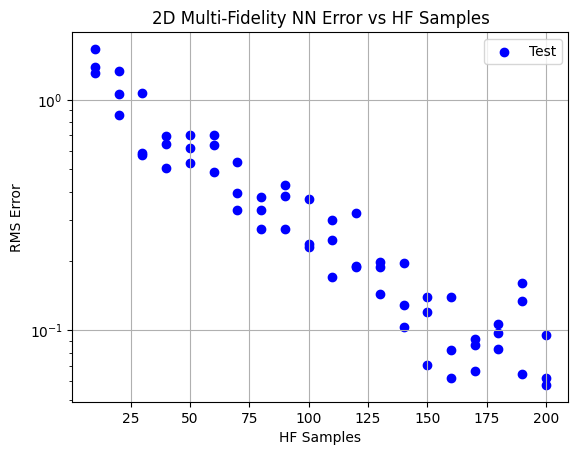

In [5]:
points_2d = []
model_error_2d = []
training_time_2d = []
evaluation_time_2d = []
points_2d, model_error_2d, evaluation_time_2d, training_time_2d = mf_nn_helpers.generate_mf_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    n_lf=800,
    sample_low=10,
    sample_high=201,
    step_size=10,
    seeds=3,
    points=points_2d,
    model_error=model_error_2d,
    training_time=training_time_2d,
    evaluation_time=evaluation_time_2d,
    lf_nn_dim=[30, 30, 10],
    hf_nl_nn_dim=[16, 16, 16],
    epochs_lf=30000,
    epochs_mf=30000,
    lr_lf=1e-4,
    wd_lf=1e-6,
    lr_mf=1e-4,
    wd_mf=1e-6,
    output_file="mf_nn_model_comparison_2d.csv",
)
ax = nn_helpers.plot_error_measure(points_2d, model_error_2d, "2D Multi-Fidelity NN Error vs HF Samples")
ax.set_xlabel("HF Samples")
nn_helpers.save_plot(ax, "2D_sweep_mf_nn")
plt.show()

### 4-Dimensional Dataset

800 LF samples, with the HF samples swept from 20 to 400 in steps of 20 for 3 seeds. The LF network, test points, and training settings match the 4D sweep in `SingleFidelityComparisonMLP.ipynb`, so the errors compare directly with `nn_model_comparison_4d.csv`. The composite uses the `[16, 16, 16]` nonlinear network, the best size from the 2D size sweep in `CompositeNN_2DSpotCheck.ipynb`.

In [6]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)

In [7]:
points_4d = []
model_error_4d = []
training_time_4d = []
evaluation_time_4d = []
points_4d, model_error_4d, evaluation_time_4d, training_time_4d = mf_nn_helpers.generate_mf_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    n_lf=800,
    sample_low=20,
    sample_high=401,
    step_size=40,
    seeds=3,
    points=points_4d,
    model_error=model_error_4d,
    training_time=training_time_4d,
    evaluation_time=evaluation_time_4d,
    lf_nn_dim=[30, 30, 10],
    hf_nl_nn_dim=[16, 16, 16],
    epochs_lf=30000,
    epochs_mf=30000,
    lr_lf=1e-4,
    wd_lf=1e-6,
    lr_mf=1e-4,
    wd_mf=1e-6,
    output_file="mf_nn_model_comparison_4d.csv",
)
ax = nn_helpers.plot_error_measure(points_4d, model_error_4d, "4D Multi-Fidelity NN Error vs HF Samples")
ax.set_xlabel("HF Samples")
nn_helpers.save_plot(ax, "4D_sweep_mf_nn")
plt.show()

Run 4D :: seed 0 :: lf points 800 :: hf points 20 :: error 24.791645665496233 :: train_time 324.0474830999883 
Run 4D :: seed 0 :: lf points 800 :: hf points 60 :: error 14.56516372006971 :: train_time 324.640456499983 
Run 4D :: seed 0 :: lf points 800 :: hf points 100 :: error 4.450189573653658 :: train_time 322.81124069998623 
Run 4D :: seed 0 :: lf points 800 :: hf points 140 :: error 3.4169964482794266 :: train_time 313.3493761999853 
Run 4D :: seed 0 :: lf points 800 :: hf points 180 :: error 2.7666155706570357 :: train_time 325.8276580999809 
Run 4D :: seed 0 :: lf points 800 :: hf points 220 :: error 2.280593698242624 :: train_time 323.2373966999876 
Run 4D :: seed 0 :: lf points 800 :: hf points 260 :: error 2.9566980311633815 :: train_time 321.1312224999856 
Run 4D :: seed 0 :: lf points 800 :: hf points 300 :: error 1.491877661306413 :: train_time 320.70777939999243 
Run 4D :: seed 0 :: lf points 800 :: hf points 340 :: error 4.231458846570217 :: train_time 322.0874254999944

KeyboardInterrupt: 